# Testedos algoritmos KMeans e DBSCAN

In [2]:
from sklearn.cluster import KMeans, DBSCAN

In [3]:
from sklearn.datasets import load_wine

In [46]:
vinhos = load_wine()

In [ ]:
print(vinhos.DESCR)

In [47]:
X = vinhos.data
y = vinhos.target

In [7]:
X.shape

(178, 13)

In [9]:
import numpy as np

In [10]:
np.set_printoptions(precision=4, suppress=True)

In [11]:
print(X[0])

[  14.23    1.71    2.43   15.6   127.      2.8     3.06    0.28    2.29
    5.64    1.04    3.92 1065.  ]


In [29]:
kmeans = KMeans(n_clusters=3)
dbscan = DBSCAN(eps=2, min_samples=5)

In [30]:
clusters_km = kmeans.fit_predict(X)
clusters_db = dbscan.fit_predict(X)

In [15]:
clusters_km

array([1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2,
       1, 1, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 2,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 0, 0, 2,
       0, 0, 2, 2, 2, 0, 0, 1, 2, 0, 0, 0, 2, 0, 0, 2, 2, 0, 0, 0, 0, 0,
       2, 2, 0, 0, 0, 0, 0, 2, 2, 0, 2, 0, 2, 0, 0, 0, 2, 0, 0, 0, 0, 2,
       0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,
       0, 2, 2, 2, 2, 0, 0, 0, 2, 2, 0, 0, 2, 2, 0, 2, 2, 0, 0, 0, 0, 2,
       2, 2, 0, 2, 2, 2, 0, 2, 0, 2, 2, 0, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 0], dtype=int32)

In [17]:
np.unique(clusters_km, return_counts=True)

(array([0, 1, 2], dtype=int32), array([69, 47, 62]))

In [31]:
np.unique(clusters_db, return_counts=True)

(array([-1]), array([178]))

In [33]:
from sklearn.preprocessing import StandardScaler

In [34]:
X_scaled = StandardScaler().fit_transform(X)

In [36]:
print(X_scaled[0])

[ 1.5186 -0.5622  0.2321 -1.1696  1.9139  0.809   1.0348 -0.6596  1.2249
  0.2517  0.3622  1.8479  1.013 ]


# Testes com o dataset normalizado

In [61]:
kmeans = KMeans(n_clusters=3)
dbscan = DBSCAN(eps=2.5, min_samples=5)

In [62]:
clusters_km = kmeans.fit_predict(X_scaled)
clusters_db = dbscan.fit_predict(X_scaled)

In [53]:
np.unique(clusters_km, return_counts=True)

(array([0, 1, 2], dtype=int32), array([64, 51, 63]))

In [63]:
np.unique(clusters_db, return_counts=True)

(array([-1,  0]), array([ 24, 154]))

In [64]:
import matplotlib.pyplot as plt

In [66]:
vinhos.feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

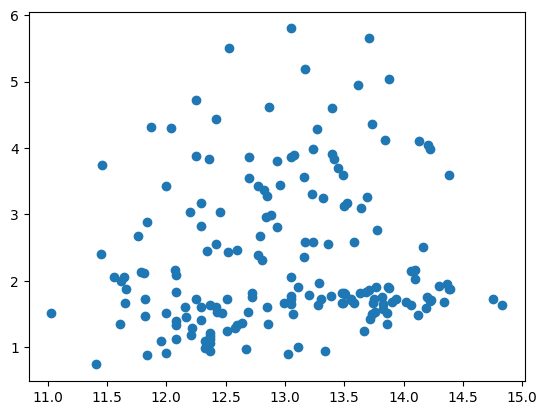

In [67]:
plt.scatter(X[:, 0], X[:, 1])
plt.show()

# PCA

In [68]:
from sklearn.decomposition import PCA

In [69]:
pca = PCA(n_components=2)

In [76]:
X_pca = pca.fit_transform(X_scaled)

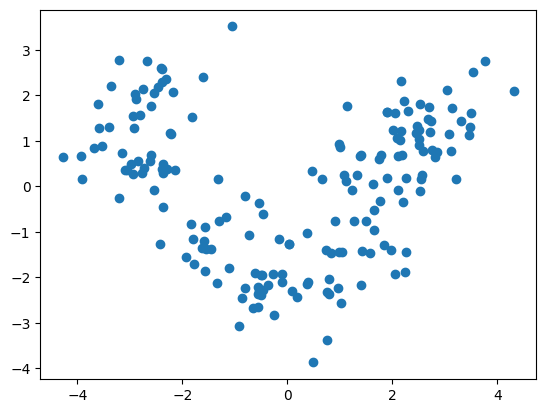

In [77]:
plt.scatter(X_pca[:, 0], X_pca[:, 1])
plt.show()

In [72]:
pca.explained_variance_

array([4.7324, 2.5111])

In [73]:
pca.explained_variance_ratio_

array([0.362 , 0.1921])

In [78]:
pca.components_

array([[ 0.1443, -0.2452, -0.0021, -0.2393,  0.142 ,  0.3947,  0.4229,
        -0.2985,  0.3134, -0.0886,  0.2967,  0.3762,  0.2868],
       [ 0.4837,  0.2249,  0.3161, -0.0106,  0.2996,  0.065 , -0.0034,
         0.0288,  0.0393,  0.53  , -0.2792, -0.1645,  0.3649]])

# KMeans e DBSCAN com PCA

In [86]:
kmeans = KMeans(n_clusters=3)
dbscan = DBSCAN(eps=0.7, min_samples=5)

In [87]:
clusters_km = kmeans.fit_predict(X_pca)
clusters_db = dbscan.fit_predict(X_pca)

In [88]:
np.unique(clusters_km, return_counts=True)

(array([0, 1, 2], dtype=int32), array([50, 67, 61]))

In [89]:
np.unique(clusters_db, return_counts=True)

(array([-1,  0,  1]), array([  6, 126,  46]))